# v8 — Data eksternal Chapman–Shaoxing (sinus takikardia asli + lebih banyak pasien AFL)

**Pertanyaan.** (1) Seberapa sering paket produksi v3.1 membunyikan alarm AFIB/AFL pada **sinus takikardia asli**?
v3.2/v7 hanya bisa mengukurnya pada data sintetis. (2) Apakah menambah ribuan pasien dari luar AFDB ke data latih
memperbaiki masalah takikardia **dan** deteksi AFL, sesuatu yang tidak bisa dicapai v3–v7 dengan 23 pasien AFDB?

**Data.** PhysioNet `ecg-arrhythmia` 1.0.0 (Chapman University, Shaoxing People's Hospital & Ningbo First Hospital,
CC BY 4.0): 45.152 pasien, satu EKG 12-lead 10 detik per pasien, 500 Hz, label ritme SNOMED CT. Hanya **lead II** yang
dipakai, diproses dengan front-end produksi (resample 50 Hz, deteksi R-peak, cek kualitas) → satu window 10 s per pasien.
Normal = SR, SB, ST, SA (irama sinus); AFIB = AFIB; AFL = AF (atrial flutter). SVT, AT, dll. tidak dipakai untuk training,
tetapi prediksinya dilaporkan.

| Varian | Data latih | Hipotesis (ditetapkan sebelum melihat hasil) |
|---|---|---|
| `v31` referensi | AFDB, resep v3/v3.1 (bobot kelas penuh) | Dilatih ulang di lingkungan ini supaya perbandingan berpasangan sah |
| `afdb` ablasi | AFDB, bobot lunak (= v5b) | Setara dengan v31 di AFDB |
| **`afdb_chapman` 8a (utama)** | AFDB + Chapman, bobot lunak | Di AFDB tidak lebih buruk dari v31; di Chapman alarm palsu sinus takikardia jauh lebih rendah dan AFL lebih baik daripada paket v3.1 |
| `chapman` 8b (eksploratif) | Chapman saja, bobot lunak | Model dari pasien lain menggeneralisasi ke AFDB? |
| `afdb_chapman_bersih` 8c (**ditambahkan setelah run pertama**) | AFDB + Chapman **tanpa label AFL** (Normal + AFIB saja) | Alarm palsu ST turun seperti 8a, AFL di AFDB tidak lebih buruk dari v31 |

**Mengapa 8c.** Run pertama menunjukkan label AFL bagian Ningbo tidak andal (bagian 2): Ningbo tidak punya satu pun AFIB,
tetapi ±7.200 "AFL"-nya berdetak ±88 bpm dan 86% tidak teratur, persis AFIB. 8a dilatih dengan label itu. 8c memakai
hanya label yang tidak diragukan. Hipotesis 8c ditulis sebelum hasilnya ada; 8a tetap dilaporkan apa adanya.

**Agar adil.** Fold AFDB resmi 5×5 (dibuktikan sama dengan fold tim), seed latih `2026 + 100·r + k`, hiperparameter
MicroTransformer sama. Pasien Chapman juga dibagi 5 fold per ulangan (diacak di dalam tiap ritme); pasien uji tidak pernah
ikut dilatih. Bias kelas cross-fit di AFDB (grid −7…+3) lalu dipakai juga di Chapman, seperti di produksi.

**Kriteria kandidat produksi untuk 8a (ditetapkan sebelum hasil).** (1) AFDB: Macro-F1 vs v31 tidak lebih buruk (P > 0,05) dan
tidak ada pasien AFL yang recall-nya turun ≥ 0,20; (2) Chapman: alarm palsu pada sinus takikardia paling banyak separuh
paket v3.1, dan recall AFL tidak lebih rendah dari paket v3.1; (3) uji stres: ambang Normal ≥ 135 bpm.

### Cara menjalankan di Kaggle
1. Notebook baru → **File → Import Notebook** → unggah file ini.
2. Panel kanan **Settings**: Accelerator **GPU T4 x2** (P100 tidak didukung PyTorch baru), **Internet: On**
   (butuh akun terverifikasi nomor HP).
3. **Save Version → Save & Run All (Commit)**. Notebook berjalan di server Kaggle (±3–4 jam); PC boleh dimatikan.
4. Setelah selesai, buka versi itu → tab **Output** → unduh `v8_hasil.zip`; unduh juga notebook-nya (berisi output).
   Bawa keduanya kembali ke repo: zip diekstrak di root repo (mengisi `cache/v8/`), notebook disalin ke folder ini.

Bisa juga dijalankan di WSL/Colab: data diunduh ke `../data/`, keluaran ke `../cache/v8/`. Job yang sudah ada dilewati.

In [1]:
import os, sys, subprocess, shutil, time
from pathlib import Path

REPO_URL = "https://github.com/farhanlhsn/WrapSihedaf.git"
ON_KAGGLE = Path("/kaggle/working").exists()
if not Path("chapman.py").exists():                          # Kaggle/Colab: clone repo dulu
    root = Path("/kaggle/working/WrapSihedaf") if ON_KAGGLE else Path.cwd() / "WrapSihedaf"
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(root)], check=True)
    if ON_KAGGLE and not (root / "data").exists():           # data mentah (±6 GB) di disk sementara, bukan di output
        Path("/tmp/sihedaf_data").mkdir(exist_ok=True)
        (root / "data").symlink_to("/tmp/sihedaf_data")
    os.chdir(root / "v8_chapman_shaoxing")
sys.path.insert(0, os.getcwd())
try:
    import wfdb  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=True)

import torch
free_gb = shutil.disk_usage(Path("../data").resolve() if Path("../data").exists() else "..").free / 1e9
print("cwd:", os.getcwd())
print("commit repo:", subprocess.run(["git", "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout.strip())
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | CPU {os.cpu_count()} | disk data bebas {free_gb:.0f} GB")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (training akan sangat lambat)")
assert free_gb > 8, "butuh ≥ 8 GB disk bebas untuk AFDB + Chapman"

cwd: /content/WrapSihedaf/v8_chapman_shaoxing
commit repo: e7de52e fix(v8): unduh Chapman dari mirror S3, varian 8c tanpa label AFL Ningbo, mode 2 GPU
Python 3.13.15 | torch 2.11.0+cu130 | CPU 2 | disk data bebas 75 GB
GPU: Tesla T4


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import chapman as C
cv, T = C.cv, C.T
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

## 1. Data AFDB dan fold resmi

Bila `../cache/dataset_v2_detector.npz` belum ada (mis. di Kaggle), AFDB diunduh (±600 MB) dan diekstrak ulang dengan ekstraktor
v5 (terbukti identik dengan v2). Hasilnya **harus** sama dengan sidik jari dataset tim (jumlah window, label, pasien, waktu);
sinyal X boleh sedikit berbeda bila versi pustaka berbeda, dan itu dilaporkan. Fold dibuat ulang dan dibuktikan sama.

In [3]:
t0 = time.perf_counter()
info = C.ensure_afdb()
folds = C.ensure_folds()
print(f"✓ dataset AFDB cocok dengan sidik jari tim ({time.perf_counter() - t0:.0f}s):", info)
print("✓ fold resmi sama dengan fold tim:", folds.shape)
if not info["identik_bit_demi_bit"]:
    print("⚠ nilai IBI berbeda sedikit dari PC tim (versi pustaka); perbandingan di notebook ini tetap sah karena semua varian"
          " dilatih ulang di sini")

unduh AFDB (±600 MB) ...


AFDB terunduh (0.2 mnt)
ekstrak window detektor 50 Hz dari 23 rekaman AFDB ...


  04015: 7251 window (2s)


  04043: 7065 window (2s)


  04048: 7099 window (2s)


...

  08378: 7336 window (2s)


  08405: 7332 window (2s)


  08434: 7315 window (2s)


  08455: 7209 window (2s)


✓ dataset AFDB cocok dengan sidik jari tim (58s): {'identik_bit_demi_bit': True, 'n': 165978, 'counts': [99000, 65826, 1152], 'y': '3555740bcefa5aee', 'records': '023e3250f2b6d06e', 't_start': 'c9788052eae7d50f', 'X': 'fcea1c422a58e6ec', 'M': '4905d145d0bb51ab'}
✓ fold resmi sama dengan fold tim: (5, 165978)


## 2. Data Chapman–Shaoxing

Data diunduh dari mirror resmi PhysioNet di AWS S3 (±5 GB, ±90 ribu file, paralel). Setiap file dicek dengan
`SHA256SUMS.txt` resmi; file yang sudah ada dan cocok dilewati, jadi unduhan bisa dilanjutkan. Ekstraksi memakai semua core
CPU dan mencetak progres setiap 2.500 pasien.

In [4]:
t0 = time.perf_counter()
C.download_chapman()
summ = C.build_chapman_windows()
print(f"selesai {time.perf_counter() - t0:.0f}s | pasien {summ['pasien']} (unik {summ['pasien unik']}) | window valid {summ['window valid']}")
display(pd.Series(summ["alasan"], name="pasien").sort_values(ascending=False).to_frame())
display(pd.DataFrame(summ["per ritme"]).T)

90305 file dari https://physionet-open.s3.amazonaws.com/ecg-arrhythmia/1.0.0/ (48 thread) ...


  10000/90305 file, 0.60 GB, 24 MB/s, 0.4 mnt


  20000/90305 file, 1.21 GB, 25 MB/s, 0.8 mnt


  30000/90305 file, 1.81 GB, 25 MB/s, 1.2 mnt


  40000/90305 file, 2.41 GB, 26 MB/s, 1.6 mnt


...

  42500/45152 (1.8 mnt, sisa ±0.1 mnt)


  45000/45152 (1.9 mnt, sisa ±0.0 mnt)
  45152/45152 (1.9 mnt, sisa ±0.0 mnt)


selesai 2.0 mnt
selesai 331s | pasien 45152 (unik 45152) | window valid 42040


,pasien
ok,42040
lebih dari satu kode ritme,1159
tanpa kode ritme,948
2 IBI di luar 300–2000 ms,259
3 IBI di luar 300–2000 ms,124
4 IBI di luar 300–2000 ms,78
5 IBI di luar 300–2000 ms,67
terlalu sedikit detak (2 IBI < 4),60
terlalu sedikit detak (3 IBI < 4),52
terlalu sedikit detak (1 IBI < 4),43


,pasien,window valid,kelas,detak median
AFIB,1780,1696,AFIB,89.291805
AFL,7978,7608,AFL,88.937637
SA,1620,1612,Normal,73.576187
SB,15824,15654,Normal,56.027182
SR,7887,7822,Normal,74.585201
ST,7136,6937,Normal,109.630249
AFL+AT,4,0,tidak dipakai,None
AFL+AT+SR,2,0,tidak dipakai,None
AFL+AT+ST,1,0,tidak dipakai,None
AFL+AT+SVT,2,0,tidak dipakai,None


### Apakah label AFL masuk akal?

AFL sungguhan (AFDB) teratur dan cepat (AFL 2:1). Bila "AFL" sebuah sumber berdetak dan tidak teratur seperti AFIB, labelnya
tidak bisa dipakai sebagai AFL. Metrik 3 kelas di Chapman (bagian 6) karena itu memakai AFL Shaoxing saja.

In [5]:
display(pd.DataFrame(C.afl_label_check()).T.round(3))

,pasien,detak median,CV median,"CV > 0,10"
SR (Shaoxing),1809.0,74.449,0.020,0.040
ST (Shaoxing),1534.0,108.267,0.013,0.083
AFIB (Shaoxing),1696.0,89.292,0.201,0.973
AFL (Shaoxing),416.0,112.574,0.126,0.575
SR (Ningbo),6013.0,74.631,0.021,0.038
ST (Ningbo),5403.0,110.074,0.016,0.101
AFIB (Ningbo),0.0,NaN,NaN,NaN
AFL (Ningbo),7192.0,88.208,0.193,0.863
AFIB (AFDB),23.0,90.500,0.213,0.966
AFL (AFDB),7.0,139.168,0.030,0.181


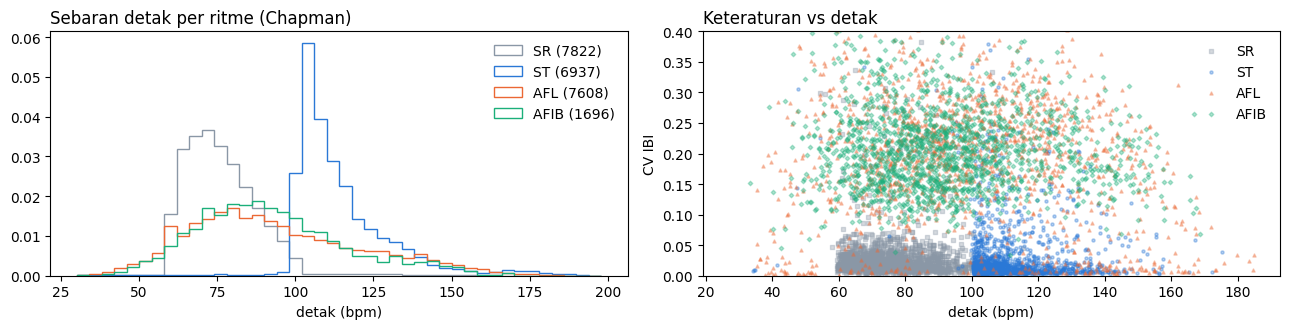

In [6]:
ch = C.load_chapman()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for g, col, mk in (("SR", "#8A97A6", "s"), ("ST", "#2a78d6", "o"), ("AFL", "#eb6834", "^"), ("AFIB", "#1baf7a", "D")):
    m = ch["rhythm"] == g
    ax[0].hist(ch["hr"][m], bins=np.arange(30, 200, 4), histtype="step", lw=1.6, color=col, label=f"{g} ({m.sum()})", density=True)
    sel = np.flatnonzero(m)[:1500]
    ax[1].scatter(ch["hr"][sel], ch["cv"][sel], s=5, alpha=.35, color=col, marker=mk, label=g)
ax[0].set_xlabel("detak (bpm)"); ax[0].legend(frameon=False); ax[0].set_title("Sebaran detak per ritme (Chapman)", loc="left")
ax[1].set_xlabel("detak (bpm)"); ax[1].set_ylabel("CV IBI"); ax[1].set_ylim(0, .4); ax[1].legend(frameon=False)
ax[1].set_title("Keteraturan vs detak", loc="left")
plt.tight_layout(); plt.show()

## 3. Uji paritas training

Varian `v31` memakai `latih.train_dl_weighted` dengan bobot pangkat 1. Fungsi itu harus identik dengan `sihedaf_cv.train_dl`
(resep v3) pada seed yang sama.

In [7]:
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
diff = C.parity_check(dev)
print(f"✓ paritas training (2 epoch): selisih maks {diff:.1e}" if diff < 1e-4 else f"⚠ selisih paritas {diff:.1e}")

✓ paritas training (2 epoch): selisih maks 0.0e+00


## 4. Training (5 varian × 5 ulangan × 5 fold)

Setiap job menyimpan OOF AFDB, OOF Chapman, prediksi uji stres, dan bobot 5 model fold ke `../cache/v8/`. Job yang sudah ada
dilewati, jadi bila sesi terputus cukup jalankan ulang.

In [8]:
C.run_all_jobs()

25 job tersisa dari 25, 1 proses (satu per GPU)


  [  5.1 mnt] v31           ulangan 0: 59 s/fold


  [ 10.0 mnt] afdb          ulangan 0: 59 s/fold


  [ 16.3 mnt] afdb_chapman  ulangan 0: 75 s/fold


  [ 17.6 mnt] chapman       ulangan 0: 16 s/fold


...

  [100.5 mnt] v31           ulangan 4: 60 s/fold


  [105.6 mnt] afdb          ulangan 4: 61 s/fold


  [112.0 mnt] afdb_chapman  ulangan 4: 76 s/fold


  [113.3 mnt] chapman       ulangan 4: 15 s/fold


  [119.4 mnt] afdb_chapman_bersih ulangan 4: 73 s/fold


## 5. Hasil di AFDB (protokol v3)

Window uji detektor 50 Hz, rata-rata 5 ulangan, bias cross-fit grid −7…+3, CI 95% bootstrap pasien. Δ berpasangan terhadap
`v31` (dilatih ulang di sini) dan terhadap ablasi `afdb`.

In [9]:
t0 = time.perf_counter()
res = C.evaluate()
print(f"evaluasi {time.perf_counter() - t0:.0f}s")
lab = res["labels"]
A = res["afdb"]
order = [k for k in ("v1", "v31", "afdb", "afdb_chapman", "chapman", "afdb_chapman_bersih") if k in A["rows"]]
display(pd.DataFrame([{"Varian": lab[k], **{m: fmt(A["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "Normal R")},
                       "alarm AFL palsu/jam": fmt(A["episodes"][k]["alarm/jam"]),
                       "deteksi episode AFL": fmt(A["episodes"][k]["deteksi episode"], 2)} for k in order]).set_index("Varian"))
pr = []
for k in ("afdb", "afdb_chapman", "chapman", "afdb_chapman_bersih"):
    for ref, P in (("v31", A["pairs"][k]), ("afdb", A["pairs_ablasi"].get(k))):
        if P is None:
            continue
        for m in ("Macro-F1", "AFL R", "Normal R"):
            pr.append({"varian": lab[k], "vs": ref, "metrik": m, "Δ": round(P[m][0], 3), "CI 95%": f"{P[m][1]:+.3f} … {P[m][2]:+.3f}",
                       "P(Δ>0)": round(P[m][3], 3), "vonis": verdict(P[m][3])})
display(pd.DataFrame(pr).set_index(["varian", "vs", "metrik"]))
display(pd.DataFrame({lab[k]: np.round(A["afl_recall"][k], 2) for k in order}, index=A["afl_patients"]).rename_axis("recall AFL"))
display(pd.DataFrame({lab[k]: {"AFL palsu total/ulangan": round(A["fp"][k]["total"]), "dari pasien tanpa AFL": round(A["fp"][k]["pasien_lain"]),
                               "bias median": np.round(A["bias"][k]["median"], 2).tolist() if k in A["bias"] else "—"} for k in order}))

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


evaluasi 2608s


,Macro-F1,AFL F1,AFL R,Normal R,alarm AFL palsu/jam,deteksi episode AFL
Varian,,,,,,
"referensi v3.1 (bobot penuh, AFDB saja)",0.830 [0.67–0.92],0.647 [0.17–0.89],0.600 [0.14–0.93],0.920 [0.84–0.96],0.560 [0.16–1.08],0.77 [0.49–0.94]
"ablasi: bobot lunak, AFDB saja (= v5b)",0.835 [0.67–0.90],0.655 [0.17–0.85],0.607 [0.15–0.85],0.928 [0.85–0.97],0.476 [0.07–1.01],0.74 [0.44–0.92]
"8a: bobot lunak, AFDB + Chapman",0.715 [0.61–0.76],0.299 [0.00–0.43],0.320 [0.00–0.51],0.915 [0.84–0.96],4.717 [2.79–7.18],0.48 [0.08–0.74]
"8b: bobot lunak, Chapman saja",0.718 [0.58–0.78],0.427 [0.04–0.58],0.351 [0.03–0.55],0.785 [0.69–0.85],1.073 [0.58–1.66],0.71 [0.40–0.88]
"8c: bobot lunak, AFDB + Chapman tanpa label AFL",0.799 [0.66–0.83],0.537 [0.15–0.60],0.479 [0.14–0.57],0.924 [0.85–0.97],0.833 [0.34–1.42],0.77 [0.55–0.93]


Δ           CI 95%  P(Δ>0)             vonis
varian                                          vs   metrik                                                    
ablasi: bobot lunak, AFDB saja (= v5b)          v31  Macro-F1  0.005  -0.015 … +0.018   0.677  tidak terbedakan
                                                     AFL R     0.007  -0.087 … +0.055   0.617  tidak terbedakan
                                                     Normal R  0.007  +0.004 … +0.011   1.000        lebih baik
8a: bobot lunak, AFDB + Chapman                 v31  Macro-F1 -0.115  -0.282 … -0.028   0.001       lebih buruk
                                                     AFL R    -0.280  -0.874 … -0.021   0.000       lebih buruk
                                                     Normal R -0.005  -0.014 … +0.003   0.097  tidak terbedakan
                                                afdb Macro-F1 -0.120  -0.267 … -0.042   0.001       lebih buruk
                                                     AFL R    -0.286  -0.789 … -0.029   0.000       lebih buruk
                                                     Normal R -0.013  -0.022 … -0.004   0.001       lebih buruk
8b: bobot lunak, Chapman saja                   v31  Macro-F1 -0.112  -0.300 … -0.024   0.000       lebih buruk
                                                     AFL R    -0.249  -0.837 … +0.004   0.187  tidak terbedakan
                                                     Normal R -0.135  -0.177 … -0.101   0.000       lebih buruk
                                                afdb Macro-F1 -0.117  -0.287 … -0.037   0.000       lebih buruk
                                                     AFL R    -0.256  -0.751 … -0.008   0.007       lebih buruk
                                                     Normal R -0.142  -0.186 … -0.107   0.000       lebih buruk
8c: bobot lunak, AFDB + Chapman tanpa label AFL v31  Macro-F1 -0.032  -0.110 … +0.009   0.228  tidak terbedakan
                                                     AFL R    -0.121  -0.416 … +0.008   0.262  tidak terbedakan
                                                     Normal R  0.004  +0.001 … +0.008   0.992        lebih baik
                                                afdb Macro-F1 -0.036  -0.100 … -0.001   0.019       lebih buruk
                                                     AFL R    -0.127  -0.327 … -0.002   0.017       lebih buruk
                                                     Normal R -0.003  -0.006 … -0.000   0.015       lebih buruk

,"referensi v3.1 (bobot penuh, AFDB saja)","ablasi: bobot lunak, AFDB saja (= v5b)","8a: bobot lunak, AFDB + Chapman","8b: bobot lunak, Chapman saja","8c: bobot lunak, AFDB + Chapman tanpa label AFL"
recall AFL,,,,,
04043,0.60,0.80,0.00,0.40,0.80
04908,0.93,0.91,0.85,0.90,0.89
04936,0.51,0.57,0.49,0.52,0.52
06426,0.18,0.25,0.09,0.10,0.18
07910,0.00,0.00,0.00,0.01,0.01
08215,0.00,0.00,0.00,0.00,0.00
08378,0.98,0.88,0.00,0.04,0.51


,"referensi v3.1 (bobot penuh, AFDB saja)","ablasi: bobot lunak, AFDB saja (= v5b)","8a: bobot lunak, AFDB + Chapman","8b: bobot lunak, Chapman saja","8c: bobot lunak, AFDB + Chapman tanpa label AFL"
AFL palsu total/ulangan,293,279,1355,346,345
dari pasien tanpa AFL,33,18,829,183,94
bias median,"[0.0, -0.5, -4.5]","[0.0, -0.5, -2.5]","[0.0, 0.25, -2.25]","[0.0, 3.0, 0.75]","[0.0, 0.0, -1.5]"


## 6. Hasil di Chapman (data eksternal)

Metrik 3 kelas pada pasien dengan ritme SR/SB/ST/SA/AFIB/AFL **berlabel andal** (AFL Ningbo dikeluarkan; lihat bagian 2).
Kolom "Macro-F1 semua label" memakai semua label, termasuk AFL Ningbo, hanya sebagai pembanding. Varian yang dilatih: OOF (pasien uji tidak ikut dilatih), bias
dari AFDB. Paket (`v31_paket`, `v2_paket`, `v1_paket`) dilatih hanya dengan AFDB, jadi seluruh Chapman adalah data uji
eksternal. CI 95% = bootstrap pasien (2.000×, bertingkat per kelas).

In [10]:
Cc = res["chapman"]
if Cc["paket_catatan"]:
    print("⚠", Cc["paket_catatan"])
keys = [k for k in ("v1_paket", "v2_paket", "v31_paket", "v31", "afdb", "afdb_chapman", "chapman", "afdb_chapman_bersih")
        if k in Cc["metrics"]]
print("pasien untuk metrik 3 kelas (label andal):", Cc["n_metrik"])
display(pd.DataFrame([{"model": lab[k], **{m: fmt(Cc["metrics"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "AFIB R", "Normal R")},
                       "Macro-F1 tanpa bias": round(Cc["metrics_tanpa_bias"][k]["Macro-F1"], 3) if k in Cc["metrics_tanpa_bias"] else "—",
                       "Macro-F1 semua label": round(Cc["metrics_semua_label"][k]["Macro-F1"], 3)}
                      for k in keys]).set_index("model"))
pr = []
for ref, P in Cc["pairs"].items():
    for k in ("afdb_chapman", "chapman", "afdb", "afdb_chapman_bersih"):
        for m in ("Macro-F1", "AFL R"):
            p = P[k][m]
            pr.append({"varian": lab[k], "vs": lab[ref], "metrik": m, "Δ": round(p[0], 3), "CI 95%": f"{p[1]:+.3f} … {p[2]:+.3f}",
                       "P(Δ>0)": round(p[3], 3), "vonis": verdict(p[3])})
display(pd.DataFrame(pr).set_index(["varian", "vs", "metrik"]))

pasien untuk metrik 3 kelas (label andal): {'Normal': 32025, 'AFIB': 1696, 'AFL': 416}


,Macro-F1,AFL F1,AFL R,AFIB R,Normal R,Macro-F1 tanpa bias,Macro-F1 semua label
model,,,,,,,
paket v1 (final.joblib),0.517 [0.51–0.52],0.083 [0.07–0.09],0.370 [0.32–0.42],0.913 [0.90–0.93],0.839 [0.83–0.84],—,0.441
paket v2,0.462 [0.46–0.47],0.067 [0.05–0.08],0.209 [0.17–0.25],0.988 [0.98–0.99],0.805 [0.80–0.81],—,0.394
paket produksi v3.1,0.520 [0.51–0.53],0.078 [0.06–0.09],0.243 [0.20–0.28],0.953 [0.94–0.96],0.865 [0.86–0.87],—,0.420
"referensi v3.1 (bobot penuh, AFDB saja)",0.531 [0.53–0.54],0.084 [0.07–0.10],0.232 [0.19–0.27],0.942 [0.93–0.95],0.882 [0.88–0.88],0.52,0.424
"ablasi: bobot lunak, AFDB saja (= v5b)",0.532 [0.53–0.54],0.086 [0.07–0.10],0.226 [0.19–0.26],0.946 [0.94–0.95],0.884 [0.88–0.89],0.525,0.424
"8a: bobot lunak, AFDB + Chapman",0.568 [0.56–0.58],0.121 [0.11–0.14],0.217 [0.19–0.24],0.726 [0.71–0.74],0.952 [0.95–0.95],0.489,0.517
"8b: bobot lunak, Chapman saja",0.543 [0.53–0.55],0.130 [0.10–0.16],0.153 [0.12–0.19],0.989 [0.98–0.99],0.908 [0.90–0.91],0.372,0.423
"8c: bobot lunak, AFDB + Chapman tanpa label AFL",0.583 [0.57–0.59],0.094 [0.07–0.12],0.078 [0.06–0.10],0.942 [0.93–0.95],0.956 [0.95–0.96],0.592,0.430


Δ           CI 95%  P(Δ>0)             vonis
varian                                          vs                                      metrik                                                    
8a: bobot lunak, AFDB + Chapman                 referensi v3.1 (bobot penuh, AFDB saja) Macro-F1  0.037  +0.030 … +0.044   1.000        lebih baik
                                                                                        AFL R    -0.015  -0.055 … +0.023   0.230  tidak terbedakan
8b: bobot lunak, Chapman saja                   referensi v3.1 (bobot penuh, AFDB saja) Macro-F1  0.012  +0.005 … +0.020   1.000        lebih baik
                                                                                        AFL R    -0.079  -0.106 … -0.052   0.000       lebih buruk
ablasi: bobot lunak, AFDB saja (= v5b)          referensi v3.1 (bobot penuh, AFDB saja) Macro-F1  0.001  -0.001 … +0.002   0.806  tidak terbedakan
                                                                                        AFL R    -0.005  -0.014 … +0.003   0.106  tidak terbedakan
8c: bobot lunak, AFDB + Chapman tanpa label AFL referensi v3.1 (bobot penuh, AFDB saja) Macro-F1  0.052  +0.045 … +0.060   1.000        lebih baik
                                                                                        AFL R    -0.153  -0.184 … -0.124   0.000       lebih buruk
8a: bobot lunak, AFDB + Chapman                 paket produksi v3.1                     Macro-F1  0.049  +0.042 … +0.056   1.000        lebih baik
                                                                                        AFL R    -0.026  -0.070 … +0.016   0.119  tidak terbedakan
8b: bobot lunak, Chapman saja                   paket produksi v3.1                     Macro-F1  0.024  +0.016 … +0.032   1.000        lebih baik
                                                                                        AFL R    -0.090  -0.121 … -0.059   0.000       lebih buruk
ablasi: bobot lunak, AFDB saja (= v5b)          paket produksi v3.1                     Macro-F1  0.012  +0.010 … +0.015   1.000        lebih baik
                                                                                        AFL R    -0.016  -0.029 … -0.004   0.004       lebih buruk
8c: bobot lunak, AFDB + Chapman tanpa label AFL paket produksi v3.1                     Macro-F1  0.064  +0.056 … +0.072   1.000        lebih baik
                                                                                        AFL R    -0.164  -0.200 … -0.132   0.000       lebih buruk

### Prediksi per ritme dan alarm palsu pada sinus takikardia asli

Angka = proporsi tebakan Normal / AFIB / AFL. Baris ST adalah pertanyaan utama v3.2: seberapa sering sinus takikardia asli
membunyikan alarm.

In [11]:
display(pd.DataFrame([{"ritme": g, "pasien": v["n"], **{lab[k]: f"{v[k][0]:.0%} / {v[k][1]:.0%} / {v[k][2]:.0%}" for k in keys}}
                      for g, v in Cc["rhythm"].items()]).set_index("ritme"))
rows = [{"kelompok": f"ST {b} bpm", "pasien": v["n"], **{lab[k]: fmt(v[k], 2) if v["n"] else "—" for k in keys}} for b, v in Cc["st_bands"].items()]
rows.append({"kelompok": "ST semua", "pasien": Cc["st_all"]["n"], **{lab[k]: fmt(Cc["st_all"][k], 2) for k in keys}})
rows.append({"kelompok": "SR/SB/SA (sinus lain)", "pasien": Cc["sinus_alarm"]["n"], **{lab[k]: fmt(Cc["sinus_alarm"][k], 2) for k in keys}})
display(pd.DataFrame(rows).set_index("kelompok").rename_axis("alarm AFIB/AFL"))
display(pd.DataFrame([{"AFL pita": b, "pasien": v["n"], **{lab[k]: (f"{v[k]:.0%}" if v[k] is not None else "—") for k in keys}}
                      for b, v in Cc["afl_bands"].items()]).set_index("AFL pita").rename_axis("AFL terdeteksi"))

,pasien,paket v1 (final.joblib),paket v2,paket produksi v3.1,"referensi v3.1 (bobot penuh, AFDB saja)","ablasi: bobot lunak, AFDB saja (= v5b)","8a: bobot lunak, AFDB + Chapman","8b: bobot lunak, Chapman saja","8c: bobot lunak, AFDB + Chapman tanpa label AFL"
ritme,,,,,,,,,
AFIB,1696,4% / 91% / 5%,1% / 99% / 0%,4% / 95% / 0%,6% / 94% / 0%,5% / 95% / 0%,6% / 73% / 22%,1% / 99% / 0%,6% / 94% / 0%
AFL (Shaoxing),416,13% / 50% / 37%,11% / 68% / 21%,14% / 61% / 24%,17% / 60% / 23%,17% / 60% / 23%,34% / 44% / 22%,23% / 62% / 15%,37% / 55% / 8%
"AFL (Ningbo, label tidak andal)",7192,10% / 80% / 10%,8% / 89% / 3%,12% / 84% / 4%,13% / 83% / 4%,13% / 83% / 4%,16% / 63% / 21%,9% / 89% / 3%,17% / 82% / 1%
SA,1612,32% / 67% / 2%,15% / 85% / 0%,42% / 58% / 0%,55% / 45% / 0%,49% / 51% / 0%,70% / 20% / 9%,49% / 50% / 0%,68% / 32% / 0%
SB,15654,98% / 2% / 0%,95% / 5% / 0%,98% / 2% / 0%,98% / 2% / 0%,99% / 1% / 0%,99% / 1% / 0%,96% / 4% / 0%,99% / 1% / 0%
SR,7822,95% / 3% / 2%,92% / 7% / 1%,97% / 2% / 1%,97% / 2% / 1%,97% / 2% / 1%,98% / 1% / 1%,96% / 4% / 0%,99% / 1% / 0%
ST,6937,51% / 8% / 41%,49% / 21% / 29%,58% / 13% / 29%,62% / 13% / 25%,65% / 12% / 23%,89% / 5% / 5%,82% / 11% / 7%,91% / 6% / 3%
AT,134,28% / 40% / 32%,25% / 62% / 13%,31% / 52% / 16%,31% / 54% / 15%,35% / 52% / 13%,44% / 39% / 17%,33% / 60% / 7%,49% / 48% / 3%
AVRT,21,67% / 0% / 33%,67% / 10% / 24%,67% / 5% / 29%,70% / 7% / 24%,70% / 6% / 24%,84% / 6% / 10%,73% / 8% / 19%,82% / 4% / 14%


,pasien,paket v1 (final.joblib),paket v2,paket produksi v3.1,"referensi v3.1 (bobot penuh, AFDB saja)","ablasi: bobot lunak, AFDB saja (= v5b)","8a: bobot lunak, AFDB + Chapman","8b: bobot lunak, Chapman saja","8c: bobot lunak, AFDB + Chapman tanpa label AFL"
alarm AFIB/AFL,,,,,,,,,
ST 100–110 bpm,3415,0.08 [0.07–0.09],0.13 [0.12–0.14],0.06 [0.06–0.07],0.06 [0.05–0.07],0.06 [0.05–0.06],0.04 [0.04–0.05],0.09 [0.08–0.09],0.04 [0.03–0.04]
ST 110–120 bpm,1639,0.82 [0.80–0.84],0.76 [0.74–0.78],0.55 [0.52–0.57],0.41 [0.39–0.43],0.33 [0.32–0.35],0.07 [0.06–0.08],0.11 [0.10–0.12],0.06 [0.05–0.07]
ST 120–130 bpm,783,0.98 [0.97–0.99],1.00 [0.99–1.00],0.98 [0.97–0.99],0.92 [0.91–0.93],0.92 [0.91–0.93],0.12 [0.10–0.14],0.16 [0.13–0.18],0.09 [0.07–0.10]
ST 130–140 bpm,484,1.00 [0.99–1.00],1.00 [1.00–1.00],1.00 [1.00–1.00],0.99 [0.98–0.99],0.99 [0.98–0.99],0.25 [0.22–0.28],0.31 [0.28–0.34],0.20 [0.17–0.23]
ST 140–150 bpm,199,1.00 [1.00–1.00],1.00 [1.00–1.00],1.00 [1.00–1.00],1.00 [0.99–1.00],1.00 [1.00–1.00],0.58 [0.53–0.63],0.86 [0.84–0.89],0.59 [0.53–0.65]
ST 150–∞ bpm,277,1.00 [1.00–1.00],1.00 [1.00–1.00],1.00 [1.00–1.00],1.00 [1.00–1.00],0.99 [0.98–0.99],0.41 [0.37–0.45],0.85 [0.82–0.87],0.27 [0.22–0.31]
ST semua,6937,0.49 [0.48–0.50],0.51 [0.49–0.52],0.42 [0.40–0.43],0.38 [0.37–0.39],0.35 [0.34–0.36],0.11 [0.10–0.12],0.18 [0.17–0.19],0.09 [0.08–0.10]
SR/SB/SA (sinus lain),25088,0.07 [0.07–0.07],0.11 [0.11–0.11],0.06 [0.05–0.06],0.05 [0.05–0.05],0.05 [0.05–0.05],0.03 [0.03–0.03],0.07 [0.07–0.07],0.03 [0.03–0.03]


,pasien,paket v1 (final.joblib),paket v2,paket produksi v3.1,"referensi v3.1 (bobot penuh, AFDB saja)","ablasi: bobot lunak, AFDB saja (= v5b)","8a: bobot lunak, AFDB + Chapman","8b: bobot lunak, Chapman saja","8c: bobot lunak, AFDB + Chapman tanpa label AFL"
AFL terdeteksi,,,,,,,,,
0–100,158,1%,0%,0%,0%,0%,12%,0%,0%
100–130,125,30%,10%,14%,13%,10%,16%,1%,1%
130–160,109,83%,50%,57%,55%,55%,38%,42%,27%
160–∞,24,100%,83%,88%,87%,89%,38%,66%,10%


## 7. Uji stres takikardia (protokol butir 9) dan sensitivitas tanpa 04936

,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
ambang (bpm) < 50% Normal,,,,
paket v1 (final.joblib),115,110,110,110
paket v2,115,115,115,110
paket produksi v3.1,115,115,115,115
"referensi v3.1 (bobot penuh, AFDB saja)",115,115,115,115
"ablasi: bobot lunak, AFDB saja (= v5b)",120,120,120,115
"8a: bobot lunak, AFDB + Chapman",140,140,140,120
"8b: bobot lunak, Chapman saja",140,140,135,135
"8c: bobot lunak, AFDB + Chapman tanpa label AFL",135,135,135,120


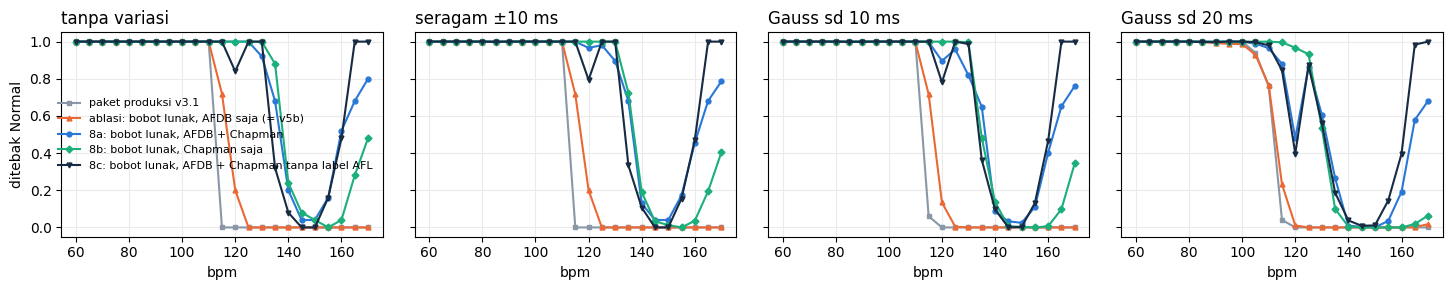

Macro-F1             AFL F1              AFL R P(v31 > model)
data         model                                                                                                                  
semua pasien referensi v3.1 (bobot penuh, AFDB saja)          0.830 [0.67–0.92]  0.647 [0.17–0.89]  0.600 [0.14–0.93]              —
             ablasi: bobot lunak, AFDB saja (= v5b)           0.835 [0.67–0.90]  0.655 [0.17–0.85]  0.607 [0.15–0.85]           0.32
             8a: bobot lunak, AFDB + Chapman                  0.715 [0.61–0.76]  0.299 [0.00–0.43]  0.320 [0.00–0.51]            1.0
             8b: bobot lunak, Chapman saja                    0.718 [0.58–0.78]  0.427 [0.04–0.58]  0.351 [0.03–0.55]            1.0
             8c: bobot lunak, AFDB + Chapman tanpa label AFL  0.799 [0.66–0.83]  0.537 [0.15–0.60]  0.479 [0.14–0.57]           0.77
tanpa 04936  referensi v3.1 (bobot penuh, AFDB saja)          0.859 [0.62–0.93]  0.734 [0.02–0.92]  0.689 [0.02–0.93]              —
             ablasi: bobot lunak, AFDB saja (= v5b)           0.837 [0.63–0.89]  0.656 [0.03–0.81]  0.601 [0.03–0.79]           0.66
             8a: bobot lunak, AFDB + Chapman                  0.624 [0.59–0.66]  0.036 [0.00–0.12]  0.096 [0.00–0.71]            1.0
             8b: bobot lunak, Chapman saja                    0.616 [0.55–0.74]  0.130 [0.01–0.49]  0.094 [0.00–0.69]            1.0
             8c: bobot lunak, AFDB + Chapman tanpa label AFL  0.727 [0.63–0.80]  0.319 [0.03–0.52]  0.257 [0.03–0.70]           0.69

In [12]:
skeys = [k for k in ("v1_paket", "v2_paket", "v31_paket", "v31", "afdb", "afdb_chapman", "chapman", "afdb_chapman_bersih")
         if k in res["threshold"]]
display(pd.DataFrame({lab[k]: res["threshold"][k] for k in skeys}).T.rename_axis("ambang (bpm) < 50% Normal"))
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
style = {"v31_paket": ("#8A97A6", "s"), "afdb": ("#eb6834", "^"), "afdb_chapman": ("#2a78d6", "o"), "chapman": ("#1baf7a", "D"),
         "afdb_chapman_bersih": ("#172B43", "v")}
for ax, j in zip(axes, res["jitters"]):
    for k, (col, mk) in style.items():
        ax.plot(res["bpms"], [t[0] for t in res["stress"][k][j]], marker=mk, color=col, ms=3.5, label=lab[k])
    ax.set_title(j, loc="left"); ax.set_xlabel("bpm"); ax.grid(color="0.92")
axes[0].set_ylabel("ditebak Normal"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
sens = []
for lab_s, s in A["sens"].items():
    for k, r in s["rows"].items():
        sens.append({"data": lab_s, "model": lab[k], **{m: fmt(r[m]) for m in ("Macro-F1", "AFL F1", "AFL R")},
                     "P(v31 > model)": round(s["pairs_v31_minus"][k][3], 2) if k in s["pairs_v31_minus"] else "—"})
display(pd.DataFrame(sens).set_index(["data", "model"]))

In [13]:
C.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(C.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
dest = Path("/kaggle/working/v8_hasil.zip") if ON_KAGGLE else C.CACHE_OUT / "v8_hasil.zip"
path, mb = C.pack_results(dest)
print(f"Ringkasan → cache/v8/ringkasan.json | hasil untuk dibawa pulang → {path} ({mb:.0f} MB)")

Ringkasan → cache/v8/ringkasan.json | hasil untuk dibawa pulang → /content/WrapSihedaf/cache/v8/v8_hasil.zip (71 MB)


## 8. Kesimpulan

**Data eksternal membuktikan masalah takikardia pada data nyata, dan sinus takikardia asli sebagai data latih hampir
menghilangkan alarm palsu itu. Tetapi dari interval RR saja, model yang belajar "cepat dan teratur = Normal" ikut kehilangan
AFL 2:1 dan SVT. Paket produksi tetap v3.1; v8 tidak dikemas.**

- **Sinus takikardia asli (6.937 pasien Chapman), alarm AFIB/AFL paket v3.1:** 42% [40–43] secara keseluruhan; 6% di 100–110 bpm,
  55% di 110–120, **98–100% di ≥ 120 bpm**. Ini konfirmasi data nyata untuk temuan sintetis v3.2.
- **Label AFL bagian Ningbo tidak andal:** 0 AFIB, tetapi 7.192 "AFL" berdetak median 88 bpm dan 86% tidak teratur, persis AFIB
  (AFL AFDB: 139 bpm, 18% tidak teratur). Metrik 3 kelas di Chapman memakai label andal saja (AFL Shaoxing, 416 pasien).
- **8a (AFDB + seluruh label Chapman): rusak di AFDB** karena label itu. Macro-F1 0,715 (P = 0,001 vs v31), 08378 0,98 → 0,00,
  alarm AFL palsu 0,56 → 4,7 per jam.
- **8b (Chapman saja): tidak menggeneralisasi ke AFDB.** Macro-F1 0,718, recall Normal 0,785.
- **8c (AFDB + Chapman tanpa label AFL; ditambahkan setelah run pertama):**
  - AFDB: Macro-F1 0,799 [0,66–0,83] vs v31 0,830 (Δ −0,032, P = 0,23, tidak terbedakan), tetapi vs ablasi `afdb` lebih buruk
    (P = 0,02). Recall AFL 0,600 → 0,479; **08378 0,98 → 0,51**. AFL palsu dari pasien tanpa AFL 33 → 94 per ulangan.
  - Chapman: alarm palsu ST **42% → 9%** (120–130 bpm: 98% → 9%; 130–140: 100% → 20%; ≥ 150: 100% → 27%). Sinus lain 6% → 3%.
    Recall Normal 0,865 → 0,956, recall AFIB 0,95 → 0,94.
  - Harganya: AFL Shaoxing terdeteksi 24% → 8% (AFL ≥ 160 bpm: 88% → 10%), dan **74% SVT kini disebut Normal** (paket v3.1
    menyebut 91% SVT sebagai AFL: kelasnya salah, tetapi setidaknya membunyikan alarm).
  - Uji stres: ambang 135 / 135 / 135 / 120 bpm (paket v3.1: 115).
  - Kriteria kandidat: (1) Macro-F1 AFDB lolos, tetapi 08378 turun 0,47 (**tidak lolos**); (2) alarm ST ≤ separuh paket lolos,
    recall AFL Chapman tidak lolos; (3) ambang ≥ 135 tidak lolos di variasi sd 20 ms.
- **Reproduksibilitas:** empat varian pertama di Colab memberi angka yang sama persis dengan run Kaggle sebelumnya.

**Untuk proyek.** Dengan data nyata, trade-off v7 terkonfirmasi dan terlihat lebih jelas. Dari interval RR saja, ritme cepat yang
teratur (sinus takikardia, AFL 2:1, SVT) tidak bisa dipisahkan. Model memilih salah satu: alarm palsu pada ST (v3.1) atau
kehilangan AFL 2:1 dan SVT (8c). Pembedanya ada di bentuk gelombang EKG (gelombang P vs gelombang flutter). Itu yang gagal di v6
karena hanya 23 pasien; sekarang tersedia 42 ribu pasien.

**Langkah berikutnya (v9):** cabang bentuk gelombang lead II 50 Hz yang dilatih dengan AFDB + Chapman (label andal), sehingga ST,
AFL 2:1, dan SVT bisa dibedakan. Butuh GPU yang lebih kuat (model EKG jauh lebih besar dari MicroTransformer).
Pertimbangkan juga kelas keempat "takikardia teratur, perlu dicek" untuk SVT/AFL 2:1/ST yang tidak bisa dipisahkan.